In [1]:
import numpy as np
import cv2
from pathlib import Path
from IPython.display import display, Image
import time

img_dir = Path("../images") if Path.cwd().name == "lam_viec" else Path("images")
img_dir.mkdir(parents=True, exist_ok=True)

def integral_image(img):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều (img.ndim == 2).")
    H, W = img.shape
    if np.issubdtype(img.dtype, np.floating):
        S = np.zeros((H + 1, W + 1), dtype=np.float64)
    else:
        S = np.zeros((H + 1, W + 1), dtype=np.int64)
    S[1:, 1:] = np.cumsum(np.cumsum(img, axis=0, dtype=S.dtype), axis=1, dtype=S.dtype)
    return S

def box_sum(S, y1, x1, y2, x2):
    return S[y2 + 1, x2 + 1] - S[y1, x2 + 1] - S[y2 + 1, x1] + S[y1, x1]

def local_mean_std(img, radius):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    H, W = img.shape
    w = 2 * radius + 1
    w2 = w * w
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    S1 = integral_image(padded)
    S2 = integral_image(padded ** 2)
    sum1 = S1[w:, w:] - S1[:-w, w:] - S1[w:, :-w] + S1[:-w, :-w]
    sum2 = S2[w:, w:] - S2[:-w, w:] - S2[w:, :-w] + S2[:-w, :-w]
    mean = sum1 / w2
    var = (sum2 / w2) - (mean ** 2)
    var = np.maximum(var, 0.0)
    std = np.sqrt(var)
    return mean, std

def adaptive_threshold(img, radius=15, method='bradley', t=0.15, k=0.34, R=128.0):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    mean, std = local_mean_std(img, radius)
    if method.lower() == 'bradley':
        T = mean * (1.0 - t)
    elif method.lower() == 'sauvola':
        T = mean * (1.0 + k * ((std / R) - 1.0))
    else:
        raise ValueError("Phương pháp không hợp lệ!")
    binary = np.where(img.astype(np.float64) < T, 255, 0).astype(np.uint8)
    return binary

def separable_filter_1d_numpy(img, radius):
    # Lọc trung bình tách được: 2 lượt 1D, mỗi lượt cộng 2r+1 lát cắt -> O(r) mỗi điểm ảnh
    w = 2 * radius + 1
    H, W = img.shape
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    rows = np.zeros((H + 2 * radius, W), dtype=np.float64)
    for dx in range(w):
        rows += padded[:, dx:dx + W]
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(w):
        out += rows[dy:dy + H, :]
    return out / (w * w)

def convolve2d(img, kernel):
    # Tích chập trực tiếp: cộng (2r+1)^2 lát cắt có trọng số -> O(r^2) mỗi điểm ảnh
    h_k, w_k = kernel.shape
    pad_h, pad_w = h_k // 2, w_k // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge').astype(np.float64)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(h_k):
        for dx in range(w_k):
            out += kernel[dy, dx] * padded[dy:dy + H, dx:dx + W]
    return out


In [2]:
test_img_path = img_dir / "sudoku.png"
if test_img_path.exists():
    real_img = cv2.imread(str(test_img_path), cv2.IMREAD_GRAYSCALE)
else:
    real_img = np.random.randint(0, 256, (256, 256), dtype=np.uint8)

# 1) Ảnh tích phân so với cv2.integral (cv2 cũng trả về mảng (H+1, W+1) có hàng/cột 0 ở đầu)
my_int = integral_image(real_img)
cv2_int = cv2.integral(real_img, sdepth=cv2.CV_64F)
print(f"Sai số integral so với cv2.integral: {np.max(np.abs(my_int - cv2_int))}")
assert np.array_equal(my_int, cv2_int.astype(np.int64))

# 2) box_sum so với cộng trực tiếp trên CHÍNH ảnh đã dùng để tạo my_int
y1, x1, y2, x2 = 10, 10, 50, 50
my_sum = box_sum(my_int, y1, x1, y2, x2)
direct_sum = int(real_img[y1:y2+1, x1:x2+1].astype(np.int64).sum())
print(f"So sánh box_sum với slicing sum: {my_sum} == {direct_sum}")
assert my_sum == direct_sum

# 3) Trung bình / độ lệch chuẩn cục bộ so với cv2.boxFilter
radius = 5
ksize = (2*radius+1, 2*radius+1)
mean_mine, std_mine = local_mean_std(real_img, radius)
f = real_img.astype(np.float64)
mean_cv2 = cv2.boxFilter(f, -1, ksize, borderType=cv2.BORDER_REPLICATE)
sq_cv2 = cv2.boxFilter(f * f, -1, ksize, borderType=cv2.BORDER_REPLICATE)
std_cv2 = np.sqrt(np.maximum(sq_cv2 - mean_cv2 ** 2, 0))
print(f"Sai số lớn nhất mean so với cv2.boxFilter: {np.max(np.abs(mean_mine - mean_cv2)):.2e}")
print(f"Sai số lớn nhất std  so với cv2.boxFilter: {np.max(np.abs(std_mine - std_cv2)):.2e}")
assert np.allclose(mean_mine, mean_cv2) and np.allclose(std_mine, std_cv2, atol=1e-6)


Sai số integral so với cv2.integral: 0.0
So sánh box_sum với slicing sum: 216282 == 216282
Sai số lớn nhất mean so với cv2.boxFilter: 2.84e-14
Sai số lớn nhất std  so với cv2.boxFilter: 2.16e-11


In [3]:
# Ảnh 3000x3000 toàn 255: tổng = 2.295e9 > giới hạn int32 (2.147e9) -> phải dùng int64
big = np.full((3000, 3000), 255, dtype=np.uint8)
S_big = integral_image(big)
assert S_big.dtype == np.int64, "Ảnh tích phân phải là int64!"
assert S_big[-1, -1] == 255 * 3000 * 3000, "Lỗi tràn số tích phân!"
assert box_sum(S_big, 0, 0, 2999, 2999) == 255 * 3000 * 3000
print(f"Tổng ảnh lớn: {S_big[-1, -1]:,} (int32 max = {np.iinfo(np.int32).max:,}) -> không tràn")
del big, S_big

for img_case in [real_img, np.zeros((100, 100), dtype=np.uint8), np.ones((100, 100), dtype=np.uint8) * 255]:
    for method in ['bradley', 'sauvola']:
        mean, std = local_mean_std(img_case, 15)
        assert np.isfinite(mean).all() and np.isfinite(std).all(), f"Lỗi NaN/Inf trong mean/std!"
        res = adaptive_threshold(img_case, radius=15, method=method)
        assert res.dtype == np.uint8 and res.shape == img_case.shape
        assert set(np.unique(res)).issubset({0, 255}), f"Lỗi đầu ra không phải {{0, 255}}!"
print("Kiểm tra an toàn (Assertions): Thành công!")


Tổng ảnh lớn: 2,295,000,000 (int32 max = 2,147,483,647) -> không tràn
Kiểm tra an toàn (Assertions): Thành công!


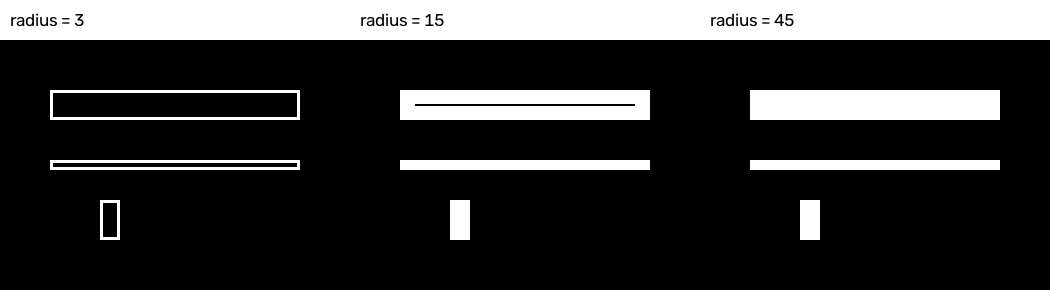

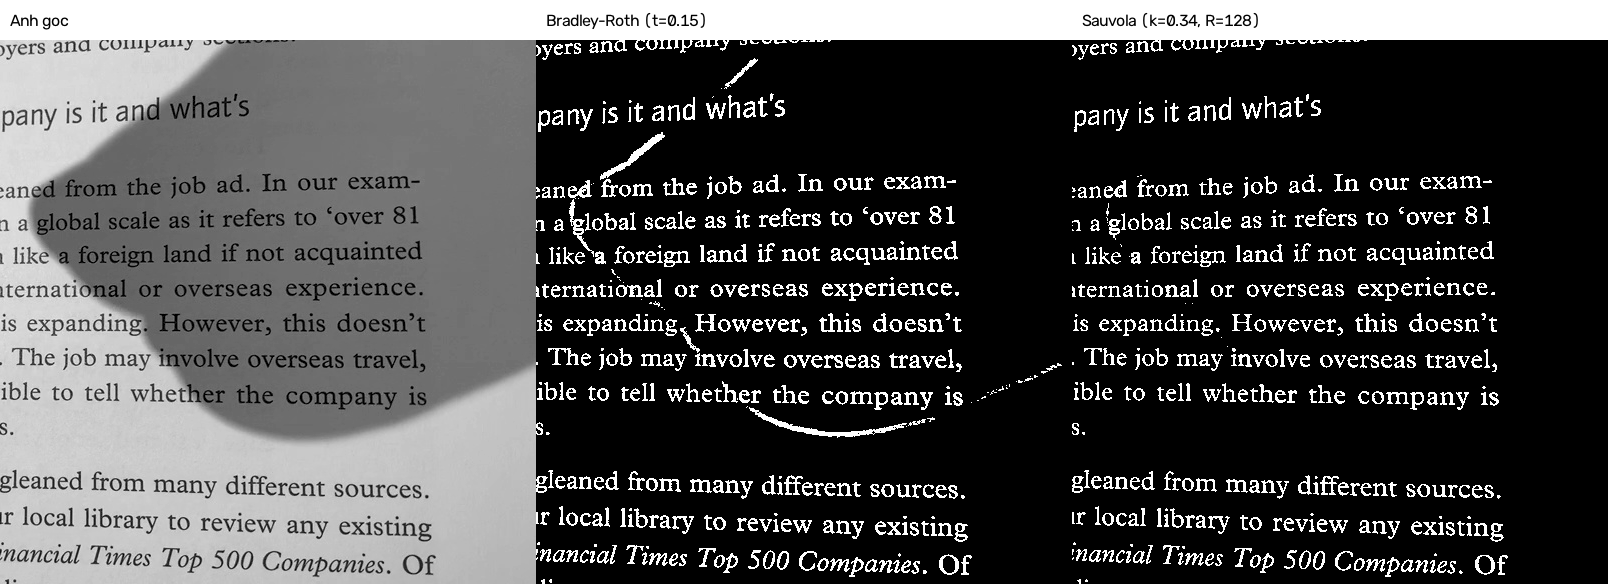

In [4]:
complex_test = np.ones((250, 350), dtype=np.uint8) * 200
complex_test[50:80, 50:300] = 40
complex_test[120:130, 50:300] = 40
complex_test[160:200, 100:120] = 40

radii = [3, 15, 45]
cell_images = []
for r in radii:
    res = adaptive_threshold(complex_test, radius=r, method='bradley', t=0.15)
    bgr = cv2.cvtColor(res, cv2.COLOR_GRAY2BGR)
    canvas = np.ones((290, 350, 3), dtype=np.uint8) * 255
    canvas[40:, :] = bgr
    cv2.putText(canvas, f"radius = {r}", (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 1, cv2.LINE_AA)
    cell_images.append(canvas)

radius_effect_path = img_dir / "radius_effect.png"
cv2.imwrite(str(radius_effect_path), np.hstack(cell_images))
display(Image(str(radius_effect_path)))

shadow_img_path = img_dir / "paper_shadow.jpg"
shadow_img = cv2.imread(str(shadow_img_path), cv2.IMREAD_GRAYSCALE) if shadow_img_path.exists() else complex_test

res_b = adaptive_threshold(shadow_img, radius=15, method='bradley', t=0.15)
res_s = adaptive_threshold(shadow_img, radius=15, method='sauvola', k=0.34, R=128.0)

c_b = cv2.cvtColor(res_b, cv2.COLOR_GRAY2BGR)
c_s = cv2.cvtColor(res_s, cv2.COLOR_GRAY2BGR)
H_img, W_img = res_b.shape

c_o = cv2.cvtColor(shadow_img, cv2.COLOR_GRAY2BGR)
canvas_flat = np.ones((H_img + 40, W_img * 3, 3), dtype=np.uint8) * 255
canvas_flat[40:, 0:W_img] = c_o
canvas_flat[40:, W_img:W_img*2] = c_b
canvas_flat[40:, W_img*2:W_img*3] = c_s
cv2.putText(canvas_flat, "Anh goc", (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 1, cv2.LINE_AA)
cv2.putText(canvas_flat, "Bradley-Roth (t=0.15)", (W_img + 10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 1, cv2.LINE_AA)
cv2.putText(canvas_flat, "Sauvola (k=0.34, R=128)", (W_img*2 + 10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 1, cv2.LINE_AA)

comp_path = img_dir / "comparison_result.png"
cv2.imwrite(str(comp_path), canvas_flat)
display(Image(str(comp_path)))

Radius   | Integral O(1)   | Separable O(r)  | Direct O(r^2)  
--------------------------------------------------------------
1        | 0.00495         | 0.00083         | 0.00234        
2        | 0.00515         | 0.00113         | 0.00438        
4        | 0.00513         | 0.00170         | 0.01368        
8        | 0.00521         | 0.00273         | 0.04922        
16       | 0.00823         | 0.00545         | 0.22119        
32       | 0.00592         | 0.01009         | 0.91980        


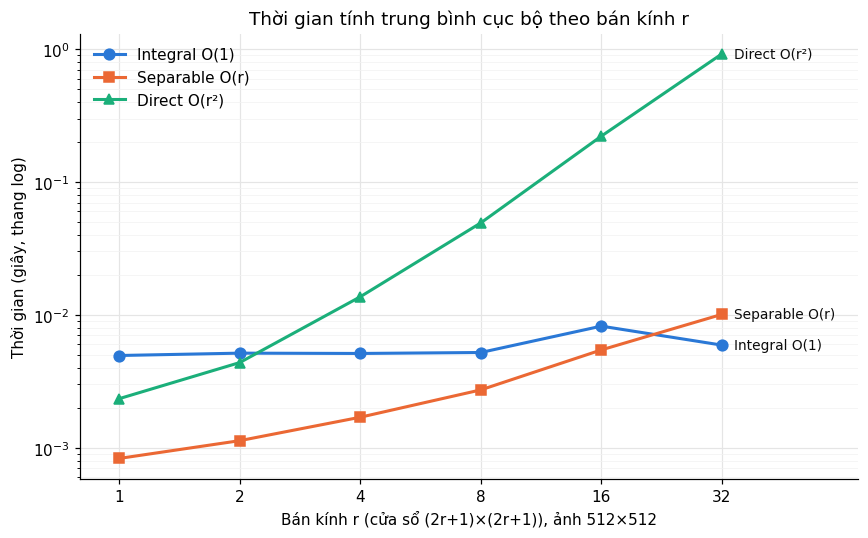


Tóm tắt:
r= 1 -> Integral: 0.00495s | Separable: 0.00083s | Direct: 0.00234s -> nhanh nhất: Separable
r= 2 -> Integral: 0.00515s | Separable: 0.00113s | Direct: 0.00438s -> nhanh nhất: Separable
r= 4 -> Integral: 0.00513s | Separable: 0.00170s | Direct: 0.01368s -> nhanh nhất: Separable
r= 8 -> Integral: 0.00521s | Separable: 0.00273s | Direct: 0.04922s -> nhanh nhất: Separable
r=16 -> Integral: 0.00823s | Separable: 0.00545s | Direct: 0.22119s -> nhanh nhất: Separable
r=32 -> Integral: 0.00592s | Separable: 0.01009s | Direct: 0.91980s -> nhanh nhất: Integral
Tỉ lệ thời gian r=32 / r=1: Integral x1.2, Separable x12.1, Direct x392.8


In [5]:
import matplotlib.pyplot as plt

radii_list = [1, 2, 4, 8, 16, 32]
dummy_img = np.random.randint(0, 256, (512, 512), dtype=np.uint8)

# Kiểm tra 3 cách cho cùng kết quả trước khi đo thời gian
r_chk = 4
k_chk = np.ones((2*r_chk+1, 2*r_chk+1)) / (2*r_chk+1) ** 2
m_int = local_mean_std(dummy_img, r_chk)[0]
assert np.allclose(m_int, separable_filter_1d_numpy(dummy_img, r_chk))
assert np.allclose(m_int, convolve2d(dummy_img, k_chk))

def bench(fn, repeat):
    best = float('inf')
    for _ in range(repeat):
        start = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - start)
    return best

t_integral, t_separable, t_direct = [], [], []
print(f"{'Radius':<8} | {'Integral O(1)':<15} | {'Separable O(r)':<15} | {'Direct O(r^2)':<15}")
print("-" * 62)
for r in radii_list:
    w = 2 * r + 1
    kernel_2d = np.ones((w, w), dtype=np.float64) / (w * w)
    t1 = bench(lambda: local_mean_std(dummy_img, radius=r), 5)
    t2 = bench(lambda: separable_filter_1d_numpy(dummy_img, radius=r), 5)
    t3 = bench(lambda: convolve2d(dummy_img, kernel_2d), 3 if r <= 8 else 1)
    t_integral.append(t1); t_separable.append(t2); t_direct.append(t3)
    print(f"{r:<8} | {t1:<15.5f} | {t2:<15.5f} | {t3:<15.5f}")

# local_mean_std tính cả mean lẫn std (2 ảnh tích phân) nên hằng số lớn hơn,
# nhưng thời gian gần như không đổi theo r; hai cách còn lại tăng theo r và r^2.
series = [("Integral O(1)", t_integral, "#2a78d6", "o"),
          ("Separable O(r)", t_separable, "#eb6834", "s"),
          ("Direct O(r²)", t_direct, "#1baf7a", "^")]

fig, ax = plt.subplots(figsize=(8, 5), dpi=110)
for name, ts, color, marker in series:
    ax.plot(radii_list, ts, color=color, marker=marker, markersize=7, linewidth=2, label=name)
    ax.annotate(name, (radii_list[-1], ts[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color="#0b0b0b")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(radii_list)
ax.set_xticklabels([str(r) for r in radii_list])
ax.set_xlim(0.8, 70)
ax.set_xlabel("Bán kính r (cửa sổ (2r+1)×(2r+1)), ảnh 512×512")
ax.set_ylabel("Thời gian (giây, thang log)")
ax.set_title("Thời gian tính trung bình cục bộ theo bán kính r")
ax.grid(True, which="major", color="#e5e5e5", linewidth=0.8)
ax.grid(True, which="minor", axis="y", color="#f2f2f2", linewidth=0.5)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()

chart_path = img_dir / "time_complexity.png"
fig.savefig(chart_path, bbox_inches="tight")
plt.show()

print("\nTóm tắt:")
for r, t_i, t_s, t_d in zip(radii_list, t_integral, t_separable, t_direct):
    fastest = min(('Integral', t_i), ('Separable', t_s), ('Direct', t_d), key=lambda x: x[1])[0]
    print(f"r={r:2d} -> Integral: {t_i:.5f}s | Separable: {t_s:.5f}s | Direct: {t_d:.5f}s -> nhanh nhất: {fastest}")
print(f"Tỉ lệ thời gian r=32 / r=1: Integral x{t_integral[-1]/t_integral[0]:.1f}, "
      f"Separable x{t_separable[-1]/t_separable[0]:.1f}, Direct x{t_direct[-1]/t_direct[0]:.1f}")
